# 🔧 Setup

In [ ]:
from pipeline import get_preprocessing_pipeline, get_feature_names, get_target_name, build_model_pipeline

from sklearn.model_selection import (train_test_split, GridSearchCV)
from sklearn.base import BaseEstimator
from sklearn.metrics import (accuracy_score, recall_score, precision_score, average_precision_score, precision_recall_curve, auc)

from sklearn.linear_model import (LogisticRegression)


import data_loader
from evaluation import (plot_roc_pr_old, plot_roc_pr)
from data_visualizer import create_fig

PATH_DATA ='data/raw/Telco_customer_churn.xlsx'
SEED = 4586

# 📦 Train-Test split

In [2]:
df = data_loader.load_churn_data(PATH_DATA)

In [3]:
X = df[get_feature_names(False)]
y = df[get_target_name(False)]

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=SEED, stratify=y)
y_test.value_counts()

Churn Value
0    1294
1     467
Name: count, dtype: int64

# 🎯 Métricas alvo
>- **`recall`** >= `0.80` : `recall` é a porcentagem de casos positivos (nesse caso `churn_value = 1`) que o modelo capturou. Um recall 0.80 significa que, de todos os clientes que realmente cancelaram, o modelo identificou corretamente 80%. Um `recall` baixo significa que o modelo não está detectando muitos dos casos positivos.
>- **`precision`** >= `0.65` :  `precision` é a porcentagem de predições positivas que o modelo acertou. Um precision de 0.65 significa que, dos clientes que o modelo apontou como estando em risco, 65% realmente cancelaram (e portanto tem `churn_value = 1`). Um `precision` baixo significa que o modelo está retornando muitos falsos positivos.

Vamos fazer ajustes para chegar o mais perto possível dessas métricas com todos os nossos modelos, inclusive o baseline.
>- **`GridSearchCV`** Testará diferentes parâmetros do modelo para encontrar o que performa melhor, e testará esses parâmetros em fatias diferentes do dataset para checar consistência
>- **`evaluation.get_oof_proba`** Retornará a probabilidade de `churn_value = 1` calculada pelo modelo, assim nos deixando determinar uma probabilidade mínima (`threshold`) em vez de utilizar o default de nossos modelos
>- **`evaluation.plot_roc_pr`** Desenhará gráficos ROC e PR:
>- **`Um gráfico ROC (Receiver Operating Characteristic) curve`** plota `True Positive Rate x False Positive Rate` ao longo de `threshold`. A área em baixo dessa curva (`AUC - Area Under The Curve`) nos diz a qualidade desse modelo, `0.5` é um modelo que não performa melhor que simplesmente escolher aleatoriamente, e `1.0` é um modelo perfeito.
>- **`Um gráfico PR (Precision-Recall) curve`** plota `Precision x Recall` ao longo de `threshold`. A `AUC` nos diz a qualidade desse modelo. Sua baseline é a `porcentagem de casos positivos no nosso database` (no nosso caso, ~`0.26`) e `1.0` é um modelo perfeito.

# 📝 Baseline
Faremos um modelo simples de LogisticRegression para servir como um baseline aos nossos modelos mais complexos.

In [5]:
def train_test_model(model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_pred, y_test)
    prec = precision_score(y_pred, y_test)
    rec = recall_score(y_pred, y_test)
    print(acc, prec, rec)

In [6]:
param_grids = {
    'lr':{
        'model__solver': ['saga'],
        'model__l1_ratio': [0, 0.25, 0.5, 0.75, 1],  # 0 = pure L2, 1 = pure L1
        'model__C': [0.1, 1.0, 10.0],
        'model__max_iter': [1000],  # Increased so saga converges cleanly
        'model__class_weight':['balanced']
        }
    }

In [7]:
model_lr = LogisticRegression()
pipeline_lr = build_model_pipeline(
        model_lr,
        scale=True
    )

models = {
        'lr':pipeline_lr
    }

train_test_model(pipeline_lr, X_train, y_train, X_test, y_test)

0.8097671777399205 0.556745182012848 0.6701030927835051


In [8]:
grid_search = GridSearchCV(
    estimator = pipeline_lr,
    param_grid = param_grids['lr'],
    cv=5,
    scoring='average_precision',
    n_jobs=-1
    )

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Val AUC-PR:", round(grid_search.best_score_, 4))

Best Parameters: {'model__C': 0.1, 'model__class_weight': 'balanced', 'model__l1_ratio': 0.5, 'model__max_iter': 1000, 'model__solver': 'saga'}
Best Cross-Val AUC-PR: 0.6708


In [9]:
probas = {
    name: evaluation.get_oof_proba(m, X_train, y_train, seed=SEED) for name, m in models.items()
    }

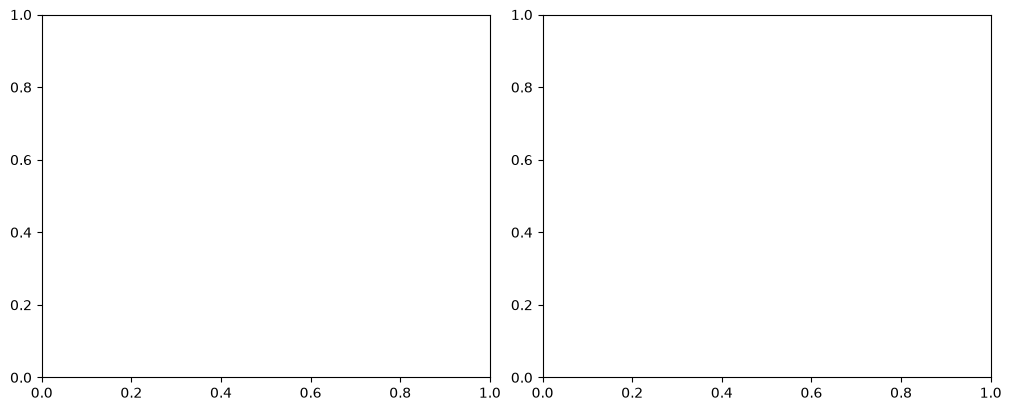

In [ ]:
fig, axs = create_fig(
    nplots=2,
    ncols=2,
    figsize=(10, 4)
)

In [ ]:
# evaluation.plot_pr(
#     y_true,
#     y_proba,
#     axs.flatten()[0],
#     plot_line_args={})

In [ ]:

# evaluation.plot_roc_pr(y_train, probas, target_recall=0.80, min_precision=0.65)
# evaluation.get_threshold_for_recall(y_train, probas['lr'], target_recall=0.80)

ValueError: Setting a random_state has no effect since shuffle is False. You should leave random_state to its default (None), or set shuffle=True.

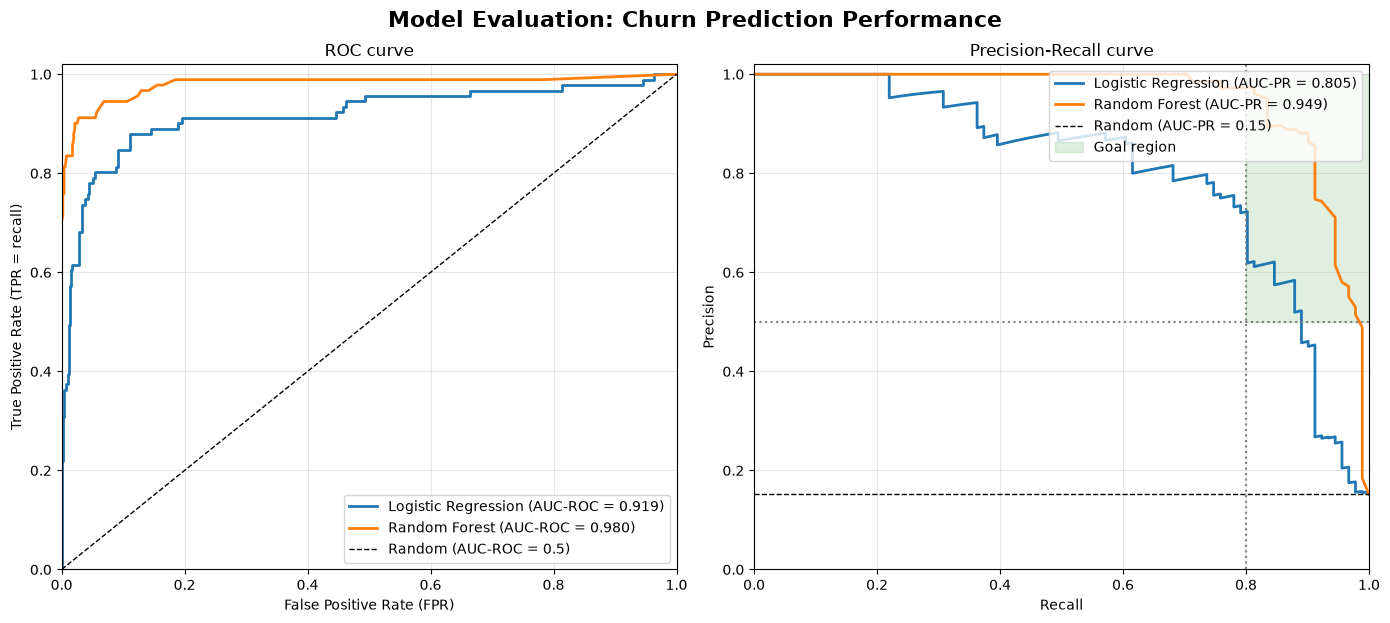

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score
)

from evaluation import (plot_roc_pr_old, plot_roc_pr)


# --- 1. Generate Fake Dataset & Train Models ---
np.random.seed(42)

# Create an imbalanced binary classification dataset (e.g., customer churn)
X, y = make_classification(
    n_samples=2000, 
    n_features=10, 
    n_informative=6, 
    n_classes=2, 
    weights=[0.85, 0.15], # ~15% churn rate (prevalence)
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Train two different classifiers
lr_model = LogisticRegression(random_state=42)
lr_model.fit(X_train, y_train)

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Collect out-of-fold or test set probabilities for P(y=1)
probas = {
    "Logistic Regression": lr_model.predict_proba(X_test)[:, 1],
    "Random Forest": rf_model.predict_proba(X_test)[:, 1]
}


# --- 2. Test the plot_roc_pr Function ---
fig, (ax_roc, ax_pr) = plot_roc_pr_old(
    y_true=y_test,
    probas=probas,
    target_recall=0.80,    # Target business recall goal (80%)
    min_precision=0.50,    # Minimum acceptable precision (50%)
    figsize=(14, 6)
)

# Optional global figure title
fig.suptitle("Model Evaluation: Churn Prediction Performance", fontsize=16, fontweight='bold', y=1.03)

plt.show()

TypeError: cannot unpack non-iterable NoneType object

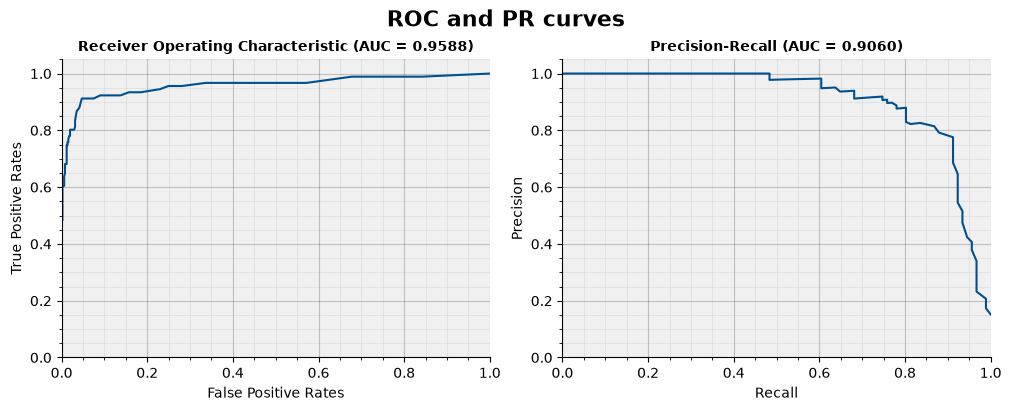

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score
)

from evaluation import (plot_roc_pr_old, plot_roc_pr, get_oof_proba)


# --- 1. Generate Fake Dataset & Train Models ---
np.random.seed(42)

# Create an imbalanced binary classification dataset (e.g., customer churn)
X, y = make_classification(
    n_samples=2000, 
    n_features=10, 
    n_informative=6, 
    n_classes=2, 
    weights=[0.85, 0.15], # ~15% churn rate (prevalence)
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Train two different classifiers
lr_model = LogisticRegression(random_state=42)
lr_model.fit(X_train, y_train)

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Collect out-of-fold or test set probabilities for P(y=1)
probas = {
    "Logistic Regression": get_oof_proba(lr_model, X_test, y_test, seed=7),
    "Random Forest": get_oof_proba(rf_model, X_test, y_test, seed=7)
}


# --- 2. Test the plot_roc_pr Function ---
fig, (ax_roc, ax_pr) = plot_roc_pr(
    y_true=y_test,
    y_proba=probas['Random Forest']
)
